# 2026-10-16 NSF diagnostics across infall stages (six original + SF proximity)

Combine the two 20261006 source notebooks without changing them. Compare
**NSF only**
across pre-peak, close-to-peak and post-peak stages, versus stellar surface
density and deprojected radius. The six original observables are corrected log10
[O III]/Hbeta, [N II]/Halpha, ([S II]6716+6730)/Halpha, the **linear**
corrected [S II]6716/6730 doublet ratio, intrinsic Halpha dispersion, and
the original linear PROXY_EWHA in Angstrom. Product names 5006/6730 correspond
to the conventional plotted 5007/6731 labels.

## Estimator requested for this notebook

For each stage, selection, observable and interval, first calculate the median
of the finite selected pixels in each supported galaxy, then take the
**equally weighted arithmetic mean of those galaxy medians**:

\[
m_g=\operatorname{median}_{i\in g}(x_i),\qquad
\hat\theta=\frac{1}{N_{\rm contributing\ galaxies}}\sum_g m_g.
\]

This differs from a median of medians, a pooled pixel median, and the median of
an equal-galaxy mixture CDF. For the three BPT observables, x is the **log10
ratio**; the mean remains in log space. No mean-of-flux ratio is used.
The sensitivity branch retains the exact median of pooled supported pixels.
Within each stage, 10,000 whole-galaxy bootstrap samples are shared across all
seven diagnostics, categories and intervals. Every draw recomputes the mean of
the resampled galaxy medians (or the pooled median with galaxy multiplicity).
Bands are the 16th--84th percentiles. Empty galaxies have no finite median and
are omitted from that draw's denominator; empty draws remain NaN. Their number
is reported. These are galaxy-bootstrap intervals, not spaxel error bars.

## Inherited selection and support

Retain the source inclination <80 deg, usable-disc geometry, Balmer detection,
SF complement, strict SNR_POSTFIT>25, and 0.25-wide density/radius intervals.
No TNSF or EW-restricted NSF subsets are analyzed. The source NSF support
decision is made once per galaxy/interval:
>=50 usable pixels, >=20 finite NSF intrinsic-dispersion pixels, and >=25
distinct selected NSF gas bins; a stage needs >=5 qualifying NSF products.
This dispersion-based support also applies to the EW, doublet and SF-proximity profiles
to keep the source footprint. Individual observables have no extra count
gate. Their actual contributor counts are reported, so an observable may
have fewer than five contributing galaxies. The stage
gate is fixed from observed NSF support and is not reapplied in bootstrap draws.

BPT ratios retain the source common six-line detection gate (raw CUT_SN/NOISE,
finite positive corrected fluxes, finite corrected Halpha surface intensity).
The doublet independently requires both sulfur lines to pass those thresholds
with finite positive corrected fluxes; it does not require [O III]/[N II]
detection. EW and dispersion use their own finite pixels. Thus seven diagnostics
share NSF support but can have different measurement footprints. The doublet
ratio is not clipped to an assumed physical range or converted to density.
Non-positive intrinsic-dispersion radicands remain unavailable. The 0--120 km/s
display cap does not truncate measurements, tables or bootstrap draws.

## Interpretation boundary

This is the first empirical comparison discussed in
[Testing NSF Components](https://chatgpt.com/c/6ad09a2e-b224-83ec-af20-b3ec9a0bf01b).
Density and radius are separate marginal profiles, not simultaneous matching.
Stage differences alone cannot distinguish changing source weights, shocks,
AGN or gas-condition changes. No mechanism or significance is inferred here.
An EW-controlled, jointly matched experiment would be a separate analysis.
Bootstrap bands omit fitting, selection, geometry and instrumental systematics.
The fit-window provenance is shown below; 8900-A results need the planned
7000-A validation before a final science claim. Figures use plt.show(); no
savefig calls or data products are written.

Plot update (2026-10-17): retain the existing **>=5** galaxy threshold.
Bins below that threshold are shown as descriptive points when at least one
galaxy passes the original per-galaxy measurement/support requirements.
Solid segments join two fully supported bins; any adjacent segment touching a
low-count bin is dashed. Low-count points are open circles (including isolated
points). Missing measurements remain gaps. Low-count bins have no shaded
bootstrap band and remain excluded from supported stage inference/contrasts.

SF-proximity update (2026-10-18): add projected distance [kpc] from each selected
NSF spaxel to the nearest selected SF spaxel with strict EW(Halpha) > 20 Angstrom
and SNR_POSTFIT > 25, across the full valid product field. The inherited SF/NSF
classification remains unchanged. Celestial WCS and the gas-product DIST_MPC
header set the projected physical distance; this is not deprojected. Missing
references or invalid distances produce NaN. The new diagnostic uses the same
density/radius bins, shared NSF support, and both existing estimators. Its finite
contributor counts are reported separately. High EW is an H II-region proxy,
not proof of purity; field coverage, masks, PSF and unobserved SF limit it.


In [1]:
from __future__ import annotations

import math
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
DATA_ROOT = PROJECT_ROOT / "v3tk_v7.6.8"
CATALOG_PATH = PROJECT_ROOT / "mauve_master_wiki_newclass.fits"
GEOMETRY_PATH = PROJECT_ROOT / "MAUVE_effective_radii.csv"

MASS_FILE_PATTERN = "{galid}_spatial_binning_maps_further.fits"
SFR_FILE_PATTERNS = (
    "{galid}_gas_bin_maps_further.fits",
    "{galid}_gas_BIN_maps_further.fits",
)
EW_FILE_PATTERNS = (
    "{galid}_proxy_EW_maps_further.fits",
    "{galid}_proxy_EW_maps.fits",
)
MASK_FILE_PATTERN = "{galid}_mask.fits"
SFH_FILE_PATTERN = "{galid}_sfh_maps.fits"

MASS_HDU = "LOGMASS_SURFACE_DENSITY"
BIN_HDU_MASS = "BINID"
BIN_HDU_GAS = "BIN_ID"
SFR_HDU = "LOGSFR_SURFACE_DENSITY_HII"
# All-spaxel ordinate only; SFR_HDU remains the original SF-selection map.
ALL_SFR_HDU = "LOGSFR_SURFACE_DENSITY"
EW_HDU = "PROXY_EWHA"
HALPHA_SIGMA_OBS_HDU = "HA6562_SIGMA"
HALPHA_SIGMA_CORR_HDU = "HA6562_SIGMA_CORR"
MASK_TABLE_HDU = "MASKFILE"
MASK_COLUMN = "MASK"
SFH_SNR_POSTFIT_HDU = "SNR_POSTFIT"

EW_HA_MIN = 6.0
# Distance references only; the inherited SF/NSF classification stays at EW > 6.
SF_REFERENCE_EW_HA_MIN = 20.0
HALPHA_SIGMA_MAX = 45.0
SFH_SNR_POSTFIT_MIN = 25.0
I_MAX_PRIMARY = 80.0
MIN_VALID_PIXELS_PER_BIN = 50
MIN_SF_PIXELS_PER_BIN = 20
WCS_TOLERANCE_ARCSEC = 0.05

SIGMA_BIN_WIDTH = 0.25
RADIUS_BIN_WIDTH = 0.25
FIXED_RELIABLE_RANGES = {"log_sigma_star": (7.0, 9.5), "radius_re": (0.0, 2.5)}
MASS_CONTOUR_LEVEL = 7.5

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.grid": False,
})


BALMER_LINES = ("HB4861", "HA6562")
REASON_LABELS = (
    "BPT: stable non-HII", "BPT: weak/ambiguous/unavailable", "HII SFR unavailable",
    "EW unavailable", "EW <= 6", "Dispersion unavailable", "Dispersion >= 45",
)
N_BOOTSTRAP = 10_000
RANDOM_SEED = 42
DIAGNOSTIC_MIN_PIXELS_PER_BIN = 20
MIN_DISTINCT_GAS_BINS_PER_BIN = 25
MIN_GALAXIES_PER_STAGE_BIN = 5
DISPERSION_YLIM = (0.0, 120.0)
CATEGORY_ORDER = ("NSF",)
VARIABLES = ("log_sigma_star", "radius_re")
BRANCH_LABELS = {"equal": "Equal-galaxy mean of galaxy medians", "pooled": "Pooled-spaxel median"}
STAGE_COLORS = {"pre-peak": "#2166ac", "close-to-peak": "#1a9850", "post-peak": "#d73027"}
print(f"Project root: {PROJECT_ROOT}")
print("Scope: six diagnostics; NSF only; equal-galaxy mean of medians")


SOURCE_NOTEBOOK_SHA256 = {'20261006_check_Halpha_sigma_NSF_TNSF_EWHa_lt3_by_stage.ipynb': '86b07bb97301b1057a2a7dd0d5c9e10f21f7acf67f655fce83b50a026c5bc3ab', '20261006_check_the_BPT_line_ratios_NSF_TNSF_EWHa_lt3_by_stage.ipynb': 'd15aae6cf590608e6bc581274dbb5cc1f3578edd306b7298d57081b97e9c757e'}
from scipy.spatial import cKDTree


Project root: /Users/Igniz/Desktop/ICRAR/further
Scope: six diagnostics; NSF only; equal-galaxy mean of medians


## Inherited geometry, masks, live sample and QC

In [2]:
def normalise_stage_label(value) -> str:
    mapping = {
        1: "pre-peak", 1.0: "pre-peak", "1": "pre-peak",
        2: "close-to-peak", 2.0: "close-to-peak", "2": "close-to-peak",
        3: "post-peak", 3.0: "post-peak", "3": "post-peak",
        "prepeak": "pre-peak", "pre-peak": "pre-peak",
        "close-to-peak": "close-to-peak", "closetopeak": "close-to-peak",
        "near-peak": "close-to-peak", "postpeak": "post-peak", "post-peak": "post-peak",
    }
    key = value if isinstance(value, (int, float)) else str(value).strip().lower().replace(" ", "")
    if key not in mapping:
        raise ValueError(f"Unrecognised RPS/infall stage label: {value!r}")
    return mapping[key]

def first_existing(paths):
    for path in paths:
        for candidate in (path, Path(str(path) + ".gz")):
            if candidate.exists():
                return candidate
    return None

def load_fits_map(path: Path, hdu_name: str, *, return_header: bool = False):
    with fits.open(path, memmap=True) as hdul:
        names = {hdu.name.upper() for hdu in hdul}
        if hdu_name.upper() not in names:
            raise KeyError(f"{path}: missing HDU {hdu_name}; available={sorted(names)}")
        hdu = hdul[hdu_name]
        data = np.asarray(hdu.data, dtype=float).copy()
        header = hdu.header.copy()
    return (data, header) if return_header else data

def load_ngist_mask(path: Path, shape):
    with fits.open(path, memmap=True) as hdul:
        if MASK_TABLE_HDU not in hdul:
            raise KeyError(f"{path}: missing table HDU {MASK_TABLE_HDU}")
        table = hdul[MASK_TABLE_HDU].data
        if MASK_COLUMN not in table.names:
            raise KeyError(f"{path}: missing mask column {MASK_COLUMN}; available={table.names}")
        flat = np.asarray(table[MASK_COLUMN], dtype=int)
    if flat.size != int(np.prod(shape)):
        raise ValueError(f"{path}: mask length {flat.size} cannot reshape to {shape}")
    return flat.reshape(shape)

def celestial_wcs_separation_arcsec(header_a, header_b, shape):
    wa, wb = WCS(header_a).celestial, WCS(header_b).celestial
    if not wa.has_celestial or not wb.has_celestial:
        return np.inf
    ny, nx = shape
    x = np.array([0, nx - 1, 0, nx - 1, (nx - 1) / 2])
    y = np.array([0, 0, ny - 1, ny - 1, (ny - 1) / 2])
    raa, deca = wa.pixel_to_world_values(x, y)
    rab, decb = wb.pixel_to_world_values(x, y)
    cosd = np.cos(np.deg2rad((deca + decb) / 2))
    return float(np.nanmax(np.hypot((raa - rab) * cosd, deca - decb)) * 3600.0)

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def calculate_deprojected_radius(shape, header, component_rows: pd.DataFrame):
    # Minimum elliptical R/Re over the physical components of one product.
    wcs = WCS(header).celestial
    if not wcs.has_celestial:
        raise ValueError("No celestial WCS available for radius calculation")
    yy, xx = np.indices(shape, dtype=float)
    ra, dec = wcs.pixel_to_world_values(xx, yy)
    radius = np.full(shape, np.inf, dtype=float)
    for _, component in component_rows.iterrows():
        east, north = tangent_offsets_arcsec(
            ra, dec, component.center_ra_deg, component.center_dec_deg
        )
        pa = np.deg2rad(float(component.pa_deg_east_of_north))
        major = east * np.sin(pa) + north * np.cos(pa)
        minor = east * np.cos(pa) - north * np.sin(pa)
        component_radius = np.sqrt(
            (major / float(component.a_re_arcsec)) ** 2
            + (minor / float(component.b_re_arcsec)) ** 2
        )
        radius = np.minimum(radius, component_radius)
    radius[~np.isfinite(radius)] = np.nan
    return radius

def intrinsic_sigma_from_maps(sigma_obs, sigma_corr):
    sigma2 = np.asarray(sigma_obs, dtype=float) ** 2 - np.asarray(sigma_corr, dtype=float) ** 2
    result = np.full(sigma2.shape, np.nan, dtype=float)
    valid = np.isfinite(sigma2) & (sigma2 > 0)
    result[valid] = np.sqrt(sigma2[valid])
    return result

def load_galaxy_maps(row, geometry):
    mass, mass_header = load_fits_map(row.mass_path, MASS_HDU, return_header=True)
    mass_bin = load_fits_map(row.mass_path, BIN_HDU_MASS)
    gas_bin, gas_header = load_fits_map(row.sfr_path, BIN_HDU_GAS, return_header=True)
    sfr = load_fits_map(row.sfr_path, SFR_HDU)
    ew_ha = load_fits_map(row.ew_path, EW_HDU)
    sigma_obs = load_fits_map(row.sfr_path, HALPHA_SIGMA_OBS_HDU)
    sigma_corr = load_fits_map(row.sfr_path, HALPHA_SIGMA_CORR_HDU)
    snr_postfit = load_fits_map(row.sfh_path, SFH_SNR_POSTFIT_HDU)
    shapes = {a.shape for a in (
        mass, mass_bin, gas_bin, sfr, ew_ha, sigma_obs, sigma_corr, snr_postfit
    )}
    if len(shapes) != 1:
        raise ValueError(f"{row.GALID}: map shape mismatch {sorted(shapes)}")
    wcs_sep = celestial_wcs_separation_arcsec(mass_header, gas_header, mass.shape)
    if not np.isfinite(wcs_sep) or wcs_sep > WCS_TOLERANCE_ARCSEC:
        raise ValueError(f"{row.GALID}: mass/gas WCS mismatch {wcs_sep:.4f} arcsec")
    ngist_mask = load_ngist_mask(row.mask_path, mass.shape)
    components = geometry.loc[geometry.notebook_product_id.eq(row.GALID)].copy()
    radius_re = calculate_deprojected_radius(mass.shape, mass_header, components)
    sigma_intrinsic = intrinsic_sigma_from_maps(sigma_obs, sigma_corr)
    valid = (
        np.isfinite(mass) & np.isfinite(gas_bin) & (ngist_mask == 0) & np.isfinite(radius_re)
    )
    sf = (
        valid & np.isfinite(sfr) & np.isfinite(ew_ha) & (ew_ha > EW_HA_MIN)
        & np.isfinite(sigma_intrinsic) & (sigma_intrinsic < HALPHA_SIGMA_MAX)
    )
    maps = {
        "log_sigma_star": mass,
        "log_sigma_sfr": sfr,
        "radius_re": radius_re,
        "snr_postfit": snr_postfit,
        "sigma_intrinsic": sigma_intrinsic,
        "gas_bin_id": gas_bin,
        "ew_ha": ew_ha,
        "valid_disc_mask": valid,
        "sf_mask": sf,
        "mass_header": mass_header,
        "wcs_separation_arcsec": wcs_sep,
    }
    return add_detection_categories(maps, row, ew_ha, sigma_intrinsic)

def add_detection_categories(maps, row, ew_ha, sigma_intrinsic):
    """Use Balmer-only ND and preserve the original SF selection exactly."""
    valid, sf = maps["valid_disc_mask"], maps["sf_mask"]
    detected = {}
    invalid_any = np.zeros(valid.shape, dtype=bool)
    with fits.open(row.sfr_path, memmap=True) as hdul:
        header = hdul[0].header
        sn_cut, flux_floor = float(header["CUT_SN"]), float(header["NOISE"])
        if not (np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(flux_floor) and flux_floor > 0):
            raise ValueError(f"{row.GALID}: invalid detection thresholds")
        if str(header["BPTMODE"]).strip().lower() != "both":
            raise ValueError(f"{row.GALID}: expected the original both-BPT selection")
        for line in BALMER_LINES:
            flux = np.asarray(hdul[line + "_FLUX"].data, dtype=float)
            error = np.asarray(hdul[line + "_FLUX_ERR"].data, dtype=float)
            if flux.shape != valid.shape or error.shape != valid.shape:
                raise ValueError(f"{row.GALID}: {line} shape mismatch")
            measurable = np.isfinite(flux) & np.isfinite(error) & (error > 0)
            invalid_any |= ~measurable
            with np.errstate(divide="ignore", invalid="ignore"):
                detected[line] = measurable & (flux / error >= sn_cut) & (flux >= flux_floor)
        # Do not use the old NII_HA_BPT / SII_HA_BPT ratio HDUs as class maps.
        nii = np.asarray(hdul["NII_BPT"].data).copy()
        sii = np.asarray(hdul["SII_BPT"].data).copy()
        for name, arr in (("NII_BPT", nii), ("SII_BPT", sii)):
            if arr.shape != valid.shape or not np.isin(arr[valid], [-1, 0, 1, 2, 3]).all():
                raise ValueError(f"{row.GALID}: invalid {name} class map")
        provenance = {key: header.get(key, "not recorded")
                      for key in ("CUT_SN", "NOISE", "BPTMODE", "BPTLIMIT", "DUSTLAW")}
    balmer_detected = detected["HA6562"] & detected["HB4861"]
    if np.any(sf & ~balmer_detected):
        raise AssertionError(f"{row.GALID}: original SF includes a Balmer non-detection")
    nd = valid & ~balmer_detected
    nsf = valid & balmer_detected & ~sf
    # Exclusive bookkeeping, in this order: HII gate -> EW gate -> sigma gate.
    # This is a first-failed-gate decomposition, not a unique physical cause.
    has_sfr = np.isfinite(maps["log_sigma_sfr"])
    stable_non_hii = np.isin(nii, [2, 3]) | np.isin(sii, [2, 3])
    both_hii = (nii == 1) & (sii == 1)
    conditions = (
        ~has_sfr & stable_non_hii,
        ~has_sfr & ~both_hii,
        ~has_sfr,
        ~np.isfinite(ew_ha),
        ew_ha <= EW_HA_MIN,
        ~np.isfinite(sigma_intrinsic),
        sigma_intrinsic >= HALPHA_SIGMA_MAX,
    )
    remainder = nsf.copy()
    reasons = {}
    for label, condition in zip(REASON_LABELS, conditions):
        reasons[label] = remainder & condition
        remainder &= ~condition
    if remainder.any():
        raise AssertionError(f"{row.GALID}: unexplained detected non-SF pixels")
    category_sum = sf.astype(np.int8) + nd + nsf
    assert np.array_equal(category_sum, valid.astype(np.int8))
    assert np.array_equal(np.sum(list(reasons.values()), axis=0), nsf.astype(int))
    maps.update({
        "nii_bpt_class": nii, "sii_bpt_class": sii,
        "nd_mask": nd, "nsf_mask": nsf, "balmer_detected_mask": balmer_detected,
        "line_detected": detected, "nsf_reasons": reasons,
        "nd_invalid_mask": nd & invalid_any,
        "nd_measured_below_cut_mask": nd & ~invalid_any,
        "detection_provenance": provenance,
    })
    return maps

In [3]:
def read_master_catalogue(path):
    with fits.open(path) as hdul:
        table = hdul[1].data
        frame = pd.DataFrame({
            "galaxy": [str(value).strip() for value in table["Galaxy"]],
            "logMstar": np.asarray(table["logMstar"], dtype=float),
            "stage_code": np.asarray(table["class"], dtype=float),
        })
    frame["stage"] = frame.stage_code.map(normalise_stage_label)
    return frame


def discover_products(data_root):
    rows = []
    for folder in sorted(path for path in data_root.iterdir()
                         if path.is_dir() and not path.name.endswith("_logs")):
        galid = folder.name
        rows.append({
            "GALID": galid,
            "mass_path": folder / MASS_FILE_PATTERN.format(galid=galid),
            "sfr_path": first_existing([
                folder / pattern.format(galid=galid) for pattern in SFR_FILE_PATTERNS
            ]),
            "ew_path": first_existing([
                folder / pattern.format(galid=galid) for pattern in EW_FILE_PATTERNS
            ]),
            "mask_path": folder / MASK_FILE_PATTERN.format(galid=galid),
            "sfh_path": first_existing([
                folder / SFH_FILE_PATTERN.format(galid=galid)
            ]),
        })
    return pd.DataFrame(rows)


STAGE_ORDER = ("pre-peak", "close-to-peak", "post-peak")
PANEL_ORDER = STAGE_ORDER + ("all stages",)
STAGE_LABELS = {
    "pre-peak": "Pre-peak",
    "close-to-peak": "Close-to-peak",
    "post-peak": "Post-peak",
    "all stages": "All stages",
}

master = read_master_catalogue(CATALOG_PATH)
geometry = pd.read_csv(GEOMETRY_PATH)
required_geometry = {
    "galaxy", "notebook_product_id", "mauve_infall_stage", "center_ra_deg",
    "center_dec_deg", "inclination_deg", "pa_deg_east_of_north",
    "a_re_arcsec", "b_re_arcsec",
}
missing_geometry = required_geometry - set(geometry.columns)
if missing_geometry:
    raise KeyError(f"{GEOMETRY_PATH}: missing columns {sorted(missing_geometry)}")

geometry = geometry.merge(
    master[["galaxy", "logMstar", "stage"]], on="galaxy", how="left",
    validate="one_to_one",
)
geometry["stage_from_geometry"] = geometry.mauve_infall_stage.map(normalise_stage_label)
if not geometry.stage.eq(geometry.stage_from_geometry).all():
    raise RuntimeError("Stage disagreement between the master and effective-radius catalogues")

product_meta = []
for galid, group in geometry.groupby("notebook_product_id", sort=False):
    if group.stage.nunique() != 1:
        raise RuntimeError(f"{galid}: physical components have inconsistent stages")
    product_meta.append({
        "GALID": galid,
        "components": ",".join(group.galaxy),
        "stage": group.stage.iloc[0],
        "inclination": float(group.inclination_deg.max()),
    })

inventory = pd.DataFrame(product_meta).merge(
    discover_products(DATA_ROOT), on="GALID", how="left", validate="one_to_one"
)
candidates = inventory.loc[
    inventory.stage.isin(STAGE_ORDER) & inventory.inclination.lt(I_MAX_PRIMARY)
].sort_values(["stage", "GALID"]).reset_index(drop=True)

# This first pass performs full live QC and records only range/count summaries.
# Maps are not cached so the combined notebook does not retain all galaxies in memory.
qc_rows = []
for row in candidates.itertuples(index=False):
    flags = []
    for label, path in (("mass", row.mass_path), ("sfr", row.sfr_path),
                        ("ew", row.ew_path), ("mask", row.mask_path),
                        ("sfh", row.sfh_path)):
        if not isinstance(path, Path) or not path.exists():
            flags.append(f"missing_{label}_product")
    maps = None
    if not flags:
        try:
            maps = load_galaxy_maps(row, geometry)
            valid = maps["valid_disc_mask"]
            if np.any(maps["sf_mask"] & ~valid):
                flags.append("sf_not_subset_of_valid")
        except Exception as exc:
            flags.append(f"load_error:{type(exc).__name__}:{exc}")
    if maps is not None and not flags:
        valid = maps["valid_disc_mask"]
        category_total = (
            maps["sf_mask"].astype(np.int8)
            + maps["nd_mask"].astype(np.int8)
            + maps["nsf_mask"].astype(np.int8)
        )
        if not np.array_equal(category_total, valid.astype(np.int8)):
            flags.append("category_accounting_failure")
    qc_rows.append({
        "GALID": row.GALID,
        "components": row.components,
        "stage": row.stage,
        "inclination_deg": row.inclination,
        "N_valid": int(valid.sum()) if maps is not None and not flags else 0,
        "N_NSF": int(maps["nsf_mask"].sum()) if maps is not None and not flags else 0,
        "sigma_min": float(np.nanmin(maps["log_sigma_star"][valid]))
                     if maps is not None and not flags else np.nan,
        "sigma_max": float(np.nanmax(maps["log_sigma_star"][valid]))
                     if maps is not None and not flags else np.nan,
        "radius_min": float(np.nanmin(maps["radius_re"][valid]))
                      if maps is not None and not flags else np.nan,
        "radius_max": float(np.nanmax(maps["radius_re"][valid]))
                      if maps is not None and not flags else np.nan,
        "wcs_separation_arcsec": maps["wcs_separation_arcsec"]
                                if maps is not None and not flags else np.nan,
        "QC_flag": ";".join(flags) if flags else "OK",
    })
    del maps

SAMPLE_QC = pd.DataFrame(qc_rows)
passed_ids = set(SAMPLE_QC.loc[SAMPLE_QC.QC_flag.eq("OK"), "GALID"])
sample = candidates.loc[candidates.GALID.isin(passed_ids)].copy()

display(SAMPLE_QC)
display(SAMPLE_QC.groupby(["stage", "QC_flag"], observed=True).size().rename("N_galaxies"))
for stage in STAGE_ORDER:
    n_pass = int(sample.stage.eq(stage).sum())
    n_candidate = int(candidates.stage.eq(stage).sum())
    print(f"{STAGE_LABELS[stage]}: {n_pass}/{n_candidate} products pass QC")
    if n_pass == 0:
        raise RuntimeError(f"No {stage} galaxies passed the live product QC")
print(f"Total passing products: {len(sample)}/{len(candidates)}")

Pre-peak: 8/8 products pass QC
Close-to-peak: 5/5 products pass QC
Post-peak: 13/16 products pass QC
Total passing products: 26/29


,GALID,components,stage,inclination_deg,N_valid,N_NSF,sigma_min,sigma_max,radius_min,radius_max,wcs_separation_arcsec,QC_flag
0,NGC4298,NGC4298,close-to-peak,52.0,498540,44039,6.476232,9.372817,0.002597,2.927309,0.0,OK
1,NGC4424,NGC4424,close-to-peak,61.0,172561,38973,7.113861,9.027295,0.002721,2.533259,0.0,OK
2,NGC4501,NGC4501,close-to-peak,65.0,664236,263460,6.926827,10.916401,0.002436,2.862775,0.0,OK
3,NGC4654,NGC4654,close-to-peak,61.0,659231,124396,6.043689,9.750619,0.000637,2.836630,0.0,OK
4,NGC4694,NGC4694,close-to-peak,62.0,94538,28161,6.934593,9.479634,0.004544,3.796772,0.0,OK
5,IC3392,IC3392,post-peak,68.0,94575,9195,6.969276,9.253759,0.004326,3.084733,0.0,OK
6,NGC4064,NGC4064,post-peak,70.0,179882,34479,6.811374,9.428892,0.002945,1.939061,0.0,OK
7,NGC4293,NGC4293,post-peak,67.0,261523,63907,7.243091,10.336573,0.001645,1.842599,0.0,OK
8,NGC4380,NGC4380,post-peak,61.0,502065,53815,6.694095,10.141226,0.001755,2.963534,0.0,OK
9,NGC4394,NGC4394,post-peak,32.0,180654,46546,7.352380,10.783341,0.001999,1.488715,0.0,OK


stage          QC_flag                                                                                             
close-to-peak  OK                                                                                                       5
post-peak      OK                                                                                                      13
               missing_mass_product;missing_sfr_product;missing_ew_product;missing_mask_product;missing_sfh_product     3
pre-peak       OK                                                                                                       8
Name: N_galaxies, dtype: int64

## Shared NSF support and selection accounting

Use the unchanged source support calculation for every diagnostic.

In [4]:
def complete_common_edges(minimum, maximum, width, *, lower_limit=None):
    minimum, maximum, width = float(minimum), float(maximum), float(width)
    start = float(lower_limit) if lower_limit is not None else np.floor(minimum / width) * width
    stop = (np.floor(maximum / width) + 1.0) * width
    edges = np.arange(start, stop + 0.5 * width, width)
    if not (edges[0] <= minimum and edges[-1] > maximum):
        raise AssertionError("Common edges do not enclose the live valid range")
    return edges


passing_qc = SAMPLE_QC.loc[SAMPLE_QC.QC_flag.eq("OK")]
COMMON_EDGES = {
    "log_sigma_star": complete_common_edges(
        passing_qc.sigma_min.min(), passing_qc.sigma_max.max(), SIGMA_BIN_WIDTH
    ),
    "radius_re": complete_common_edges(
        passing_qc.radius_min.min(), passing_qc.radius_max.max(),
        RADIUS_BIN_WIDTH, lower_limit=0.0,
    ),
}
VARIABLE_LABELS = {
    "log_sigma_star": r"$\log_{10}(\Sigma_\star/[M_\odot\,\mathrm{kpc}^{-2}])$",
    "radius_re": r"$R/R_e$",
}

def nsf_profile_supported(frame):
    return (frame.eligible_usable
            & frame.N_sigma_Ha.ge(DIAGNOSTIC_MIN_PIXELS_PER_BIN)
            & frame.N_unique_gas_bins.ge(MIN_DISTINCT_GAS_BINS_PER_BIN))


dispersion_rows, selection_rows = [], []
for row in sample.itertuples(index=False):
    maps = load_galaxy_maps(row, geometry)
    keep = maps["valid_disc_mask"] & np.isfinite(maps["snr_postfit"]) & (maps["snr_postfit"] > SFH_SNR_POSTFIT_MIN)
    sigma = maps["sigma_intrinsic"]
    nsf = maps["nsf_mask"] & keep
    masks = {"NSF": nsf}
    selection_rows.extend({"GALID": row.GALID, "stage": row.stage, "category": category,
        "N_usable": int(keep.sum()), "N_category": int(mask.sum()),
        "N_finite_sigma": int((mask & np.isfinite(sigma)).sum())}
        for category,mask in masks.items())
    for variable,edges in COMMON_EDGES.items():
        x = maps[variable]
        for lo,hi in zip(edges[:-1],edges[1:]):
            in_bin = np.isfinite(x) & (x >= lo) & (x < hi)
            n_usable = int((keep & in_bin).sum())
            for category,mask in masks.items():
                selected = mask & in_bin
                finite_selected = selected & np.isfinite(sigma)
                values = np.asarray(sigma[finite_selected],dtype=float)
                gas_ids = np.unique(maps["gas_bin_id"][finite_selected])
                assert np.all(np.isfinite(gas_ids)) and np.all(gas_ids == np.floor(gas_ids))
                dispersion_rows.append({"GALID":row.GALID,"stage":row.stage,
                    "variable":variable,"category":category,"bin_left":float(lo),
                    "bin_right":float(hi),"center":float((lo+hi)/2),
                    "N_usable":n_usable,"N_category":int(selected.sum()),
                    "eligible_usable":n_usable >= MIN_VALID_PIXELS_PER_BIN,
                    "N_sigma_Ha":len(values),"N_unique_gas_bins":len(gas_ids),"values_sigma_Ha":values})
    del maps
DISPERSION_BY_GALAXY_BIN = pd.DataFrame(dispersion_rows)
SELECTION_COUNTS = pd.DataFrame(selection_rows)
STAGE_COUNTS = SELECTION_COUNTS.groupby(["category","stage"],observed=True)[["N_category","N_finite_sigma"]].sum()
display(STAGE_COUNTS)


# The support decision is made once from NSF and shared across all diagnostics.
keys = ["GALID","stage","variable","bin_left"]
NSF_SUPPORT_BY_GALAXY_BIN = DISPERSION_BY_GALAXY_BIN.loc[
    DISPERSION_BY_GALAXY_BIN.category.eq("NSF"),keys +
    ["eligible_usable","N_sigma_Ha","N_unique_gas_bins"]].copy()
assert not NSF_SUPPORT_BY_GALAXY_BIN.duplicated(keys).any()
NSF_SUPPORT_BY_GALAXY_BIN["NSF_eligible_galaxy"] = nsf_profile_supported(NSF_SUPPORT_BY_GALAXY_BIN)
NSF_SUPPORT_BY_GALAXY_BIN["N_NSF_gal_stage_support"] = (
    NSF_SUPPORT_BY_GALAXY_BIN.groupby(["stage","variable","bin_left"],observed=True)
    .NSF_eligible_galaxy.transform("sum"))
NSF_SUPPORT_BY_GALAXY_BIN["eligible_stage"] = (
    NSF_SUPPORT_BY_GALAXY_BIN.N_NSF_gal_stage_support.ge(MIN_GALAXIES_PER_STAGE_BIN))
ref = NSF_SUPPORT_BY_GALAXY_BIN.rename(columns={
    "N_sigma_Ha":"N_NSF_sigma_Ha","N_unique_gas_bins":"N_NSF_unique_gas_bins"})
DISPERSION_BY_GALAXY_BIN = DISPERSION_BY_GALAXY_BIN.merge(
    ref.drop(columns="eligible_usable"),on=keys,how="left",validate="many_to_one")
# Nonempty finite data are required only to calculate an estimate.
DISPERSION_BY_GALAXY_BIN["eligible_profile"] = (
    DISPERSION_BY_GALAXY_BIN.NSF_eligible_galaxy & DISPERSION_BY_GALAXY_BIN.N_sigma_Ha.gt(0))
DISPERSION_BY_GALAXY_BIN["eligible_stage_profile"] = (
    DISPERSION_BY_GALAXY_BIN.eligible_profile & DISPERSION_BY_GALAXY_BIN.eligible_stage)
PROFILE_SUPPORT_CUT_COUNTS = NSF_SUPPORT_BY_GALAXY_BIN.groupby(
    ["stage","variable"],observed=True).NSF_eligible_galaxy.sum().rename("N_qualifying_NSF_galaxy_intervals").to_frame()
print("Shared support: >=25 distinct NSF gas bins per galaxy; >=5 qualifying NSF galaxies per stage/interval")
display(PROFILE_SUPPORT_CUT_COUNTS)

Shared support: >=25 distinct NSF gas bins per galaxy; >=5 qualifying NSF galaxies per stage/interval


N_category  N_finite_sigma
category stage                                    
NSF      close-to-peak      488865          488865
         post-peak          815887          815887
         pre-peak           929104          929104

N_qualifying_NSF_galaxy_intervals
stage         variable                                         
close-to-peak log_sigma_star                                 42
              radius_re                                      37
post-peak     log_sigma_star                                113
              radius_re                                      89
pre-peak      log_sigma_star                                 70
              radius_re                                      61

## Six original measurements plus SF proximity on the shared support

BPT masks retain their common source detection gate; doublet, EW and dispersion finite footprints are counted separately.

In [5]:
def selected_sf_reference_mask(maps):
    """High-EW subset of selected SF; leave the SF/NSF classification intact."""
    return (maps['sf_mask'] & maps['valid_disc_mask']
            & np.isfinite(maps['snr_postfit'])
            & (maps['snr_postfit'] > SFH_SNR_POSTFIT_MIN)
            & np.isfinite(maps['ew_ha'])
            & (maps['ew_ha'] > SF_REFERENCE_EW_HA_MIN))

def unit_sky_vectors(header, mask):
    y, x = np.nonzero(mask)
    ra, dec = WCS(header).celestial.pixel_to_world_values(x, y)
    ra, dec = np.deg2rad(ra), np.deg2rad(dec)
    return np.column_stack((np.cos(dec)*np.cos(ra), np.cos(dec)*np.sin(ra), np.sin(dec)))

def nearest_sf_distance(header, sf, target, distance_mpc):
    result = np.full(target.shape, np.nan)
    if not sf.any() or not target.any() or not np.isfinite(distance_mpc) or distance_mpc <= 0:
        return result
    reference = unit_sky_vectors(header, sf)
    queries = unit_sky_vectors(header, target)
    if not np.isfinite(reference).all() or not np.isfinite(queries).all():
        raise ValueError('Nonfinite WCS coordinates in SF proximity calculation')
    chord, _ = cKDTree(reference).query(queries)
    result[target] = 2*np.arcsin(np.clip(chord/2, 0, 1))*distance_mpc*1000
    return result

BPT_RAW_LINES = ("HA6562","HB4861","OIII5006","NII6583","SII6716","SII6730")
LINE_ORDER = ("HA6562","HB4861","OIII5006","NII6583","SII_SUM")
RATIO_ORDER = ("OIII_Hb","NII_Ha","SII_Ha")
RATIO_INDICES = {"OIII_Hb":(2,1),"NII_Ha":(3,0),"SII_Ha":(4,0)}
RATIO_LABELS = {
    "OIII_Hb":r"$\log_{10}([\mathrm{O\,III}]5007/\mathrm{H}\beta)$",
    "NII_Ha":r"$\log_{10}([\mathrm{N\,II}]6583/\mathrm{H}\alpha)$",
    "SII_Ha":r"$\log_{10}(([\mathrm{S\,II}]6716+6731)/\mathrm{H}\alpha)$",
}

def load_ratio_maps(row,geometry):
    maps = load_galaxy_maps(row,geometry)
    with fits.open(row.sfr_path,memmap=True) as hdul:
        cut_sn,noise = float(hdul[0].header["CUT_SN"]),float(hdul[0].header["NOISE"])
        coef = float(hdul[0].header["SFRCOEF"])
        assert np.isfinite(coef) and coef>0
        corrected,detected = {},{}
        for line in BPT_RAW_LINES:
            raw = np.asarray(hdul[line+"_FLUX"].data,dtype=float)
            error = np.asarray(hdul[line+"_FLUX_ERR"].data,dtype=float)
            corrected[line] = np.asarray(hdul[line+"_FLUX_CORR"].data,dtype=float).copy()
            assert raw.shape==error.shape==corrected[line].shape==maps["valid_disc_mask"].shape
            good = np.isfinite(raw)&np.isfinite(error)&(error>0)
            with np.errstate(divide="ignore",invalid="ignore"):
                detected[line]=good&(raw/error>=cut_sn)&(raw>=noise)
        log_lha = np.asarray(hdul["LOGSFR_SURFACE_DENSITY"].data,dtype=float).copy()-np.log10(coef)
    for line in BALMER_LINES:
        assert np.array_equal(detected[line],maps["line_detected"][line])
    common = np.logical_and.reduce([detected[line]&np.isfinite(corrected[line])&(corrected[line]>0) for line in BPT_RAW_LINES])
    common &= np.isfinite(log_lha)
    line_flux = [corrected["HA6562"],corrected["HB4861"],corrected["OIII5006"],
        corrected["NII6583"],corrected["SII6716"]+corrected["SII6730"]]
    intensity = np.full((*common.shape,5),np.nan)
    for j,flux in enumerate(line_flux):
        intensity[...,j][common]=10**log_lha[common]*(flux[common]/corrected["HA6562"][common])
    assert np.isfinite(intensity[common]).all() and (intensity[common]>0).all()
    ratios={}
    for name,(num,den) in RATIO_INDICES.items():
        value=np.full(common.shape,np.nan)
        value[common]=np.log10(line_flux[num][common]/line_flux[den][common])
        ratios[name]=value
    maps.update(common_bpt=common,line_intensities=intensity,ratio_maps=ratios)
    return maps

def nsf_selection_mask(maps):
    keep=maps["valid_disc_mask"]&np.isfinite(maps["snr_postfit"])&(maps["snr_postfit"]>SFH_SNR_POSTFIT_MIN)
    nsf=maps["nsf_mask"]&keep
    return keep, {"NSF": nsf}


DIAGNOSTIC_ORDER = RATIO_ORDER + ('SII_doublet', 'sigma_Ha', 'EW_Ha', 'distance_SF_kpc')
DIAGNOSTIC_LABELS = dict(RATIO_LABELS, **{
    'SII_doublet': r'$[\mathrm{S\,II}]6716/6731$',
    'sigma_Ha': r'$\sigma_{\mathrm{H}\alpha,\mathrm{intr}}$ [km s$^{-1}$]',
    'EW_Ha': r'EW(H$\alpha$) [$\AA$]',
    'distance_SF_kpc': 'Projected distance to SF [kpc]',
})

def load_six_diagnostics(row, geometry):
    maps = load_ratio_maps(row, geometry)
    with fits.open(row.sfr_path, memmap=True) as hdul:
        sn_cut, floor = float(hdul[0].header['CUT_SN']), float(hdul[0].header['NOISE'])
        sulfur_flux, sulfur_ok = [], []
        for line in ('SII6716', 'SII6730'):
            raw = np.asarray(hdul[line + '_FLUX'].data, dtype=float)
            err = np.asarray(hdul[line + '_FLUX_ERR'].data, dtype=float)
            corr = np.asarray(hdul[line + '_FLUX_CORR'].data, dtype=float)
            assert raw.shape == err.shape == corr.shape == maps['ew_ha'].shape
            with np.errstate(divide='ignore', invalid='ignore'):
                ok = (np.isfinite(raw) & np.isfinite(err) & (err > 0)
                      & (raw / err >= sn_cut) & (raw >= floor)
                      & np.isfinite(corr) & (corr > 0))
            sulfur_flux.append(corr)
            sulfur_ok.append(ok)
        doublet = np.full(maps['ew_ha'].shape, np.nan)
        ok = sulfur_ok[0] & sulfur_ok[1]
        doublet[ok] = sulfur_flux[0][ok] / sulfur_flux[1][ok]
        distance_mpc = float(hdul[0].header.get('DIST_MPC', np.nan))
        gas_header = hdul[BIN_HDU_GAS].header.copy()
        provenance = {key: hdul[0].header.get(key, 'not recorded')
                      for key in ('LMIN', 'LMAX', 'CUT_SN', 'NOISE', 'BPTMODE', 'DUSTLAW')}
    keep, masks = nsf_selection_mask(maps)
    sf_reference = selected_sf_reference_mask(maps)
    distance = nearest_sf_distance(gas_header, sf_reference, masks['NSF'], distance_mpc)
    provenance.update(DIST_MPC=distance_mpc, N_SF_selected=int((maps['sf_mask'] & keep).sum()),
                      N_SF_reference=int(sf_reference.sum()),
                      SF_reference_EW_min=SF_REFERENCE_EW_HA_MIN,
                      N_NSF_distance=int(np.isfinite(distance).sum()))
    diagnostics = dict(maps['ratio_maps'], distance_SF_kpc=distance, SII_doublet=doublet,
                       sigma_Ha=maps['sigma_intrinsic'], EW_Ha=maps['ew_ha'])
    return maps, diagnostics, provenance

measurement_rows, provenance_rows = [], []
for row in sample.itertuples(index=False):
    maps, diagnostics, provenance = load_six_diagnostics(row, geometry)
    provenance_rows.append(dict(GALID=row.GALID, stage=row.stage, **provenance))
    keep, masks = nsf_selection_mask(maps)
    assert np.array_equal(masks['NSF'], maps['nsf_mask'] & keep)
    for variable, edges in COMMON_EDGES.items():
        for lo, hi in zip(edges[:-1], edges[1:]):
            inside = np.isfinite(maps[variable]) & (maps[variable] >= lo) & (maps[variable] < hi)
            for category, mask in masks.items():
                selected = mask & inside
                for diagnostic, value in diagnostics.items():
                    finite = selected & np.isfinite(value)
                    values = np.asarray(value[finite], dtype=float)
                    measurement_rows.append(dict(
                        GALID=row.GALID, stage=row.stage, variable=variable, category=category,
                        diagnostic=diagnostic, bin_left=float(lo), bin_right=float(hi),
                        center=float((lo + hi) / 2), N_selected=int(selected.sum()),
                        N_pixels=len(values), values=values,
                        galaxy_median=float(np.median(values)) if len(values) else np.nan))
    del maps, diagnostics

MEASUREMENTS = pd.DataFrame(measurement_rows).merge(
    NSF_SUPPORT_BY_GALAXY_BIN[['GALID', 'stage', 'variable', 'bin_left',
        'NSF_eligible_galaxy', 'N_NSF_gal_stage_support', 'eligible_stage']],
    on=['GALID', 'stage', 'variable', 'bin_left'], how='left', validate='many_to_one')
MEASUREMENTS['contributes'] = MEASUREMENTS.NSF_eligible_galaxy & MEASUREMENTS.N_pixels.gt(0)
PRODUCT_PROVENANCE = pd.DataFrame(provenance_rows)
display(PRODUCT_PROVENANCE)
print('LMIN/LMAX are header values when recorded; missing values do not establish fit-window provenance.')
display(MEASUREMENTS.groupby(['stage', 'category', 'diagnostic'], observed=True).N_pixels.sum().unstack('diagnostic'))

LMIN/LMAX are header values when recorded; missing values do not establish fit-window provenance.


,GALID,stage,LMIN,LMAX,CUT_SN,NOISE,BPTMODE,DUSTLAW,DIST_MPC,N_SF_selected,N_SF_reference,SF_reference_EW_min,N_NSF_distance
0,NGC4298,close-to-peak,not recorded,not recorded,3,20,both,calzetti,16.5,138402,43309,20.0,43104
1,NGC4424,close-to-peak,not recorded,not recorded,3,20,both,calzetti,16.5,8994,4217,20.0,37811
2,NGC4501,close-to-peak,not recorded,not recorded,3,20,both,calzetti,16.5,251607,78476,20.0,261968
3,NGC4654,close-to-peak,not recorded,not recorded,3,20,both,calzetti,16.5,320781,166203,20.0,117845
4,NGC4694,close-to-peak,not recorded,not recorded,3,20,both,calzetti,16.5,1058,337,20.0,28137
5,IC3392,post-peak,not recorded,not recorded,3,20,both,calzetti,16.5,13888,3576,20.0,9123
6,NGC4064,post-peak,not recorded,not recorded,3,20,both,calzetti,16.5,3273,1882,20.0,33921
7,NGC4293,post-peak,not recorded,not recorded,3,20,both,calzetti,16.5,471,154,20.0,63400
8,NGC4380,post-peak,not recorded,not recorded,3,20,both,calzetti,16.5,56075,11000,20.0,51190
9,NGC4394,post-peak,not recorded,not recorded,3,20,both,calzetti,16.5,30430,6296,20.0,45294


,diagnostic,EW_Ha,NII_Ha,OIII_Hb,SII_Ha,SII_doublet,distance_SF_kpc,sigma_Ha
stage,category,,,,,,,
close-to-peak,NSF,977730,683566,683566,683566,915904,977730,977730
post-peak,NSF,1631774,1105416,1105416,1105416,1204566,1631774,1631774
pre-peak,NSF,1858208,1109168,1109168,1109168,1611056,1858208,1858208


## Exact estimators and whole-galaxy resampling

The equal branch uses np.mean/np.nanmean of galaxy medians. The pooled branch retains the source exact order-statistic algorithm.

In [6]:
def median_profile_draws(arrays, indices, weights, eligible_stage=True):
    """Mean of galaxy medians; exact pooled median with whole-galaxy multiplicities."""
    arrays = [np.asarray(a,dtype=float) for a in arrays]
    assert all(np.isfinite(a).all() for a in arrays)
    counts = np.array([len(a) for a in arrays],dtype=np.int64)
    central = {b:np.nan for b in BRANCH_LABELS}
    draws = {b:np.full(len(indices),np.nan) for b in BRANCH_LABELS}
    if not eligible_stage or not counts.sum():
        return central,draws
    medians = np.array([np.median(a) if len(a) else np.nan for a in arrays])
    central['equal'] = float(np.mean(medians[np.isfinite(medians)]))
    sampled = medians[indices]
    nonempty = np.isfinite(sampled).any(axis=1)
    draws['equal'][nonempty] = np.nanmean(sampled[nonempty],axis=1)
    values = np.concatenate(arrays)
    labels = np.repeat(np.arange(len(arrays)),counts)
    order = np.argsort(values,kind='stable')
    values,labels = values[order],labels[order]
    central['pooled'] = float(np.median(values))
    # CDF by galaxy permits exact medians without materializing all draw pixels.
    prefixes = np.array([np.cumsum(labels==j,dtype=np.int32) for j in range(len(arrays))])
    totals = weights @ counts
    nonempty = totals>0
    draw_weights = weights[nonempty]
    def order_statistic(ranks):
        left=np.zeros(len(ranks),dtype=np.int64)
        right=np.full(len(ranks),len(values)-1,dtype=np.int64)
        while np.any(left<right):
            middle=(left+right)//2
            cdf=np.einsum('ij,ji->i',draw_weights,prefixes[:,middle],dtype=np.int64)
            below=cdf<=ranks
            left=np.where(below,middle+1,left)
            right=np.where(below,right,middle)
        return values[left]
    low=order_statistic((totals[nonempty]-1)//2)
    high=order_statistic(totals[nonempty]//2)
    draws['pooled'][nonempty]=(low+high)/2
    return central,draws



def finite_percentiles(values):
    finite = np.asarray(values,dtype=float)
    finite = finite[np.isfinite(finite)]
    return tuple(np.percentile(finite,[16,84])) if finite.size else (np.nan,np.nan)


# Unequal galaxy sizes distinguish the three estimators; explicit draws check multiplicity.
_arrays = [np.zeros(101), np.array([2.]), np.array([10.]), np.array([])]
_indices = np.array([[0, 1, 2, 3], [2, 2, 1, 3], [3, 3, 3, 3], [0, 0, 1, 3]])
_weights = np.array([(_indices == j).sum(axis=1) for j in range(4)]).T
_central, _draws = median_profile_draws(_arrays, _indices, _weights)
assert np.isclose(_central['equal'], 4.)  # median of medians would be 2; pooled median is 0.
assert np.allclose(_draws['equal'], [4., 22/3, np.nan, 2/3], equal_nan=True)
for _i, _draw in enumerate(_indices):
    _values = np.concatenate([_arrays[j] for j in _draw])
    _expected = np.median(_values) if len(_values) else np.nan
    assert np.allclose(_draws['pooled'][_i], _expected, equal_nan=True)
print('SYNTHETIC_ESTIMATOR_CHECK_OK: mean of galaxy medians and exact pooled bootstrap')

profile_rows, PROFILE_DRAWS = [], {branch: {} for branch in BRANCH_LABELS}
for si, stage in enumerate(STAGE_ORDER):
    galaxies = sample.loc[sample.stage.eq(stage), 'GALID'].sort_values().to_numpy()
    indices = np.random.default_rng(RANDOM_SEED + 15000000 + si).integers(
        0, len(galaxies), size=(N_BOOTSTRAP, len(galaxies)))
    weights = np.array([(indices == j).sum(axis=1) for j in range(len(galaxies))]).T
    selected_stage = MEASUREMENTS.loc[MEASUREMENTS.stage.eq(stage)]
    for (variable, category, diagnostic, lo), raw in selected_stage.groupby(
            ['variable', 'category', 'diagnostic', 'bin_left'], observed=True, sort=True):
        group = raw.set_index('GALID').reindex(galaxies)
        assert group.NSF_eligible_galaxy.notna().all()
        contributes = group.contributes.to_numpy(bool)
        arrays = [np.asarray(v, dtype=float) if ok else np.array([])
                  for v, ok in zip(group['values'], contributes)]
        nsf_count = int(group.N_NSF_gal_stage_support.iloc[0])
        stage_ok = nsf_count >= MIN_GALAXIES_PER_STAGE_BIN
        central, draws = median_profile_draws(arrays, indices, weights, stage_ok)
        hi = float(group.bin_right.iloc[0])
        center = (lo + hi) / 2
        xmin, xmax = FIXED_RELIABLE_RANGES[variable]
        for branch in BRANCH_LABELS:
            key = (stage, variable, category, diagnostic, float(lo))
            PROFILE_DRAWS[branch][key] = draws[branch]
            lower, upper = finite_percentiles(draws[branch])
            profile_rows.append(dict(
                weighting=branch, stage=stage, variable=variable, category=category,
                diagnostic=diagnostic, bin_left=lo, bin_right=hi, center=center,
                N_NSF_gal_support=nsf_count, N_gal_support=int(contributes.sum()),
                N_spaxel_support=sum(len(a) for a in arrays), eligible_stage=stage_ok,
                N_finite_bootstrap=int(np.isfinite(draws[branch]).sum()),
                in_fixed_reliable_range=xmin <= center < xmax,
                display_value=(central[branch] if stage_ok else
                    (float(np.mean([np.median(a) for a in arrays if len(a)]))
                     if branch == 'equal' and any(len(a) for a in arrays) else
                     float(np.median(np.concatenate(arrays))) if any(len(a) for a in arrays) else np.nan)),
                value=central[branch], value_lo=lower, value_hi=upper))
PROFILES = pd.DataFrame(profile_rows)
SUPPORT_TABLE = PROFILES.loc[PROFILES.weighting.eq('equal') & PROFILES.in_fixed_reliable_range,
    ['category', 'diagnostic', 'stage', 'variable', 'center', 'N_NSF_gal_support',
     'N_gal_support', 'N_spaxel_support', 'eligible_stage', 'N_finite_bootstrap']]
display(SUPPORT_TABLE)

SYNTHETIC_ESTIMATOR_CHECK_OK: mean of galaxy medians and exact pooled bootstrap


,category,diagnostic,stage,variable,center,N_NSF_gal_support,N_gal_support,N_spaxel_support,eligible_stage,N_finite_bootstrap
10,NSF,EW_Ha,pre-peak,log_sigma_star,7.125,2,2,25765,False,0
12,NSF,EW_Ha,pre-peak,log_sigma_star,7.375,3,3,40111,False,0
14,NSF,EW_Ha,pre-peak,log_sigma_star,7.625,8,8,115120,True,10000
16,NSF,EW_Ha,pre-peak,log_sigma_star,7.875,8,8,232355,True,10000
18,NSF,EW_Ha,pre-peak,log_sigma_star,8.125,8,8,241886,True,10000
...,...,...,...,...,...,...,...,...,...,...
2214,NSF,sigma_Ha,post-peak,radius_re,1.375,7,7,58389,True,10000
2216,NSF,sigma_Ha,post-peak,radius_re,1.625,5,5,47988,True,9974
2218,NSF,sigma_Ha,post-peak,radius_re,1.875,4,4,37374,False,0
2220,NSF,sigma_Ha,post-peak,radius_re,2.125,3,3,25335,False,0


## Equal-galaxy profiles, then pooled-spaxel sensitivity profiles

Each diagnostic uses one NSF row and two columns (density and radius). Bands are 16th--84th percentile whole-galaxy bootstrap intervals. Shared y limits aid comparison; dispersion alone retains the source 0--120 display range.

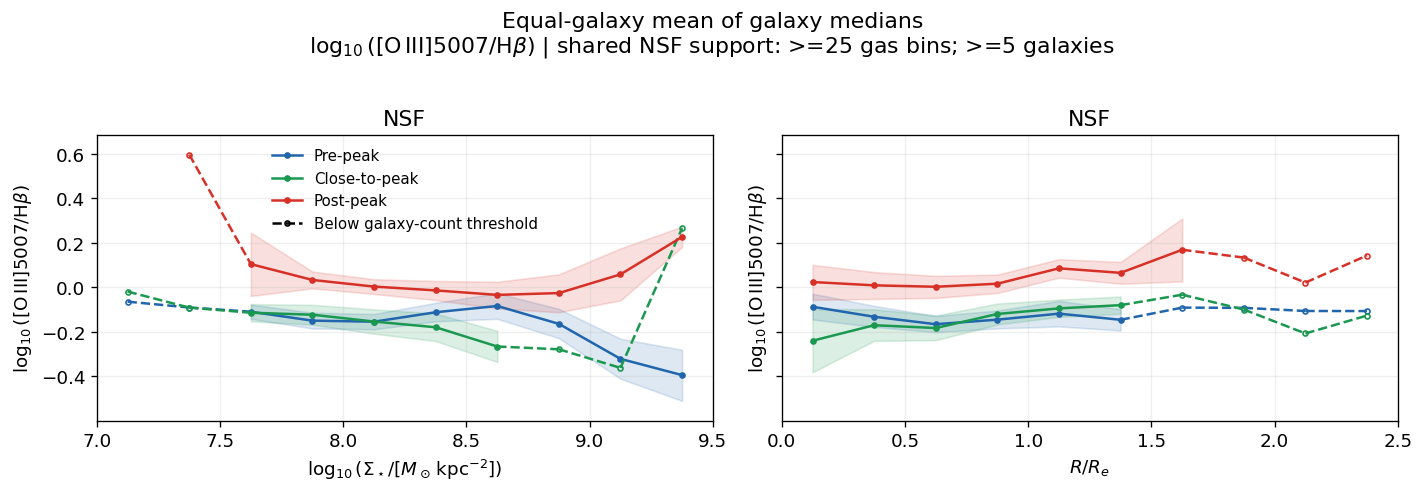

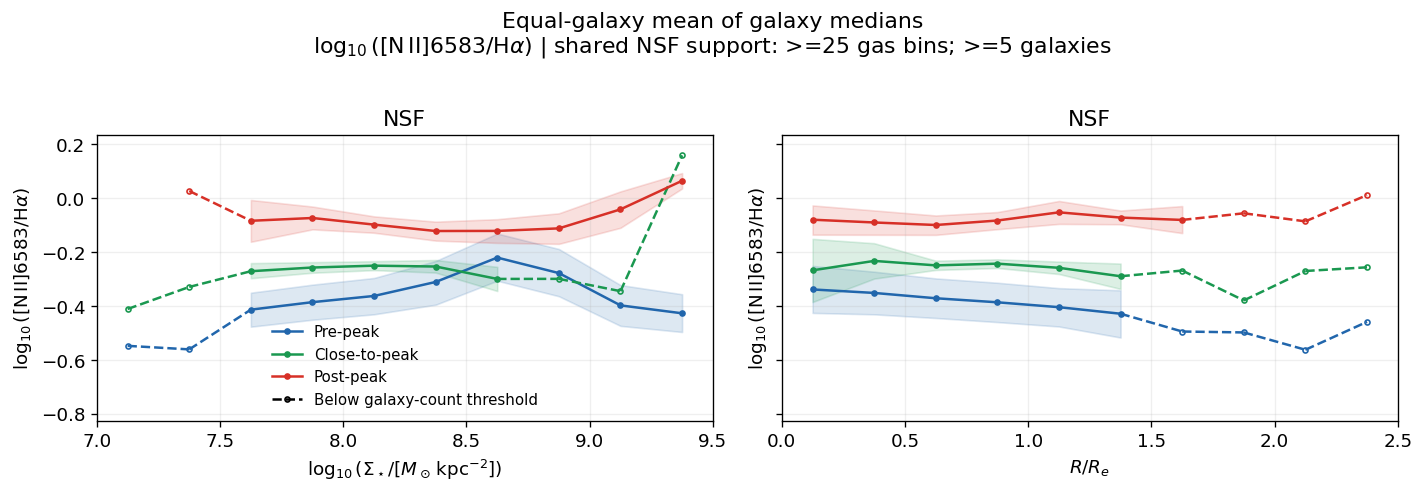

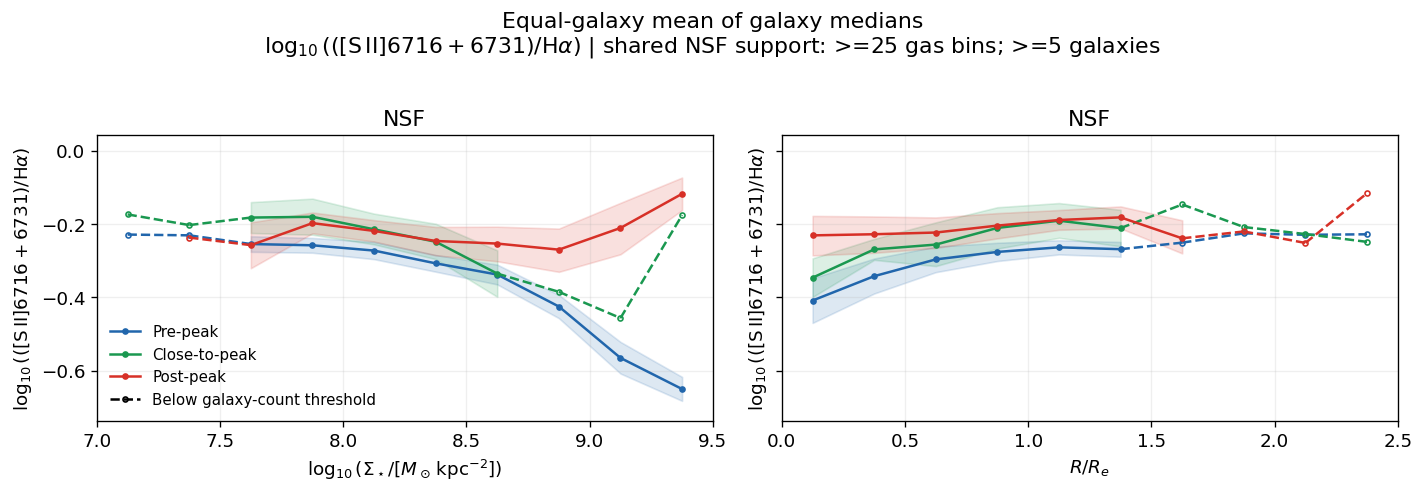

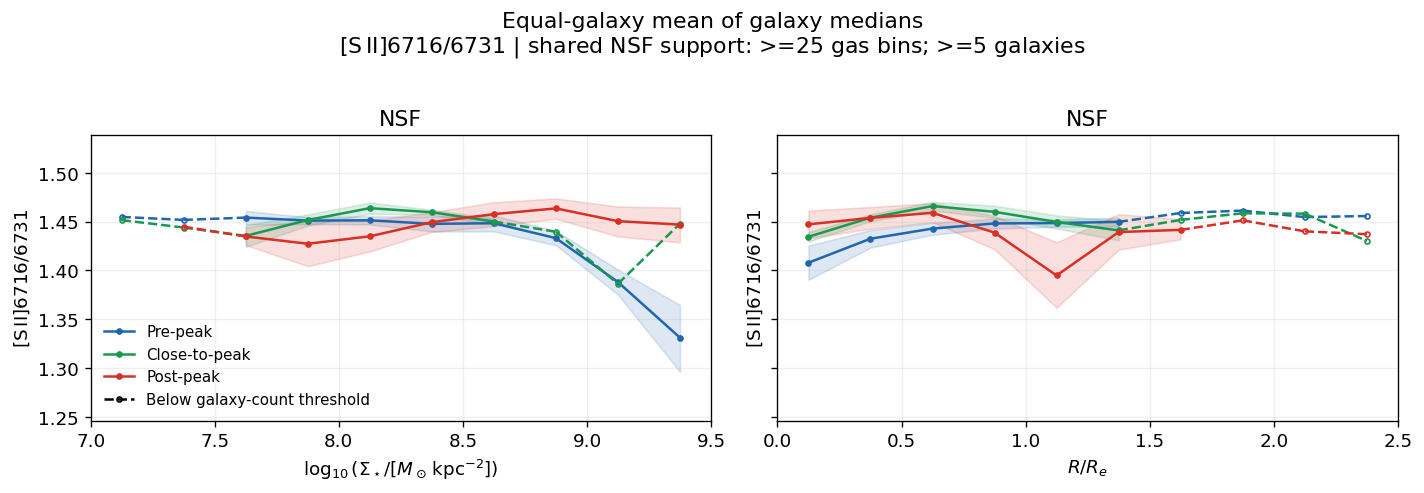

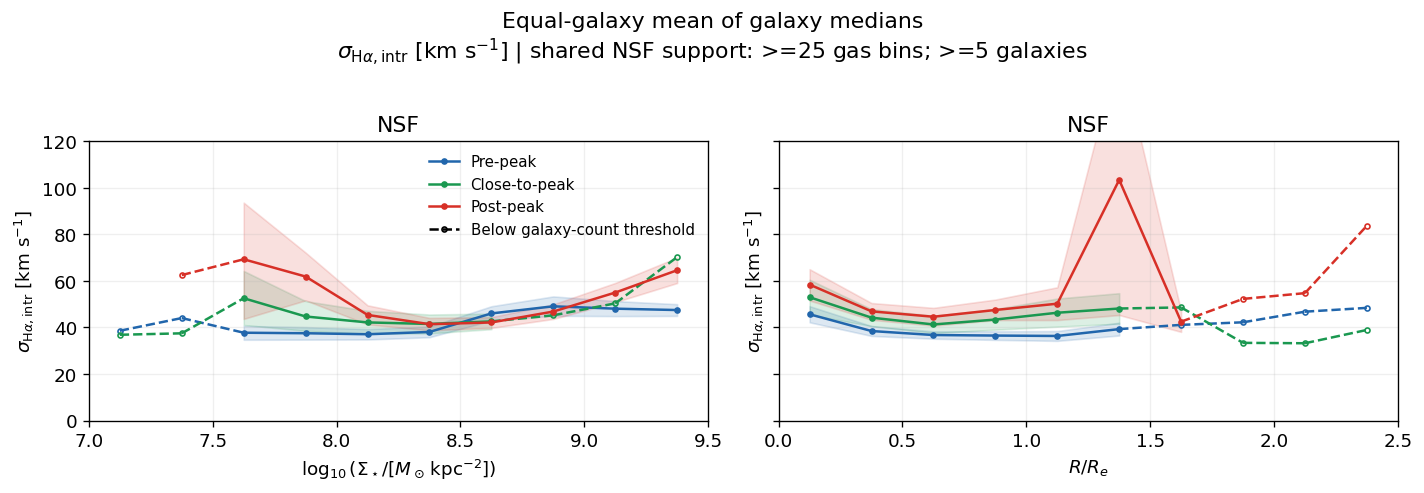

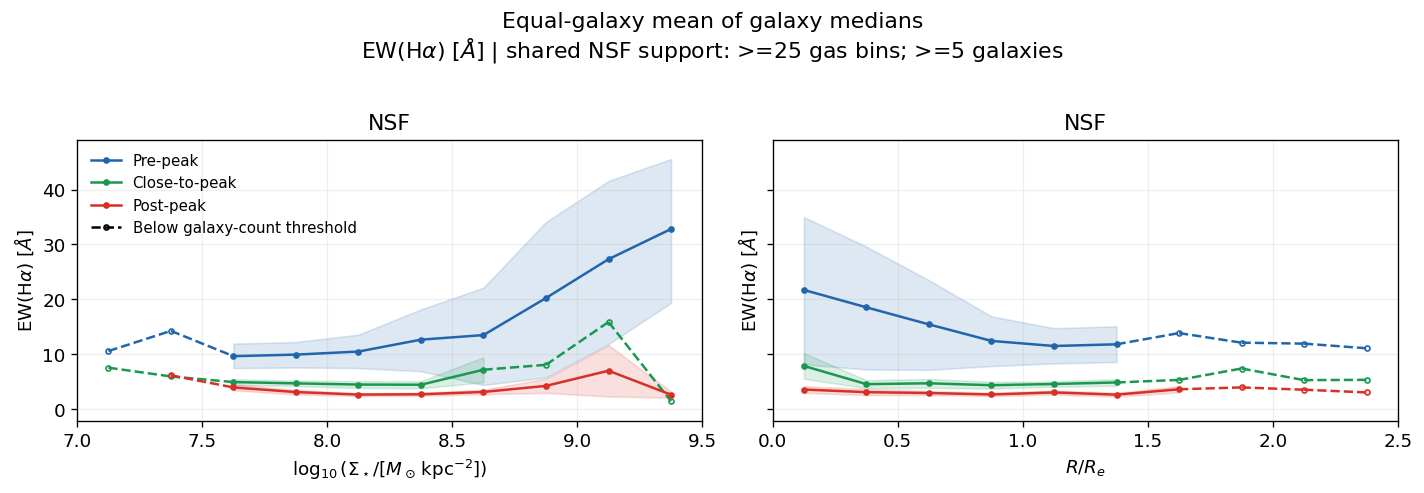

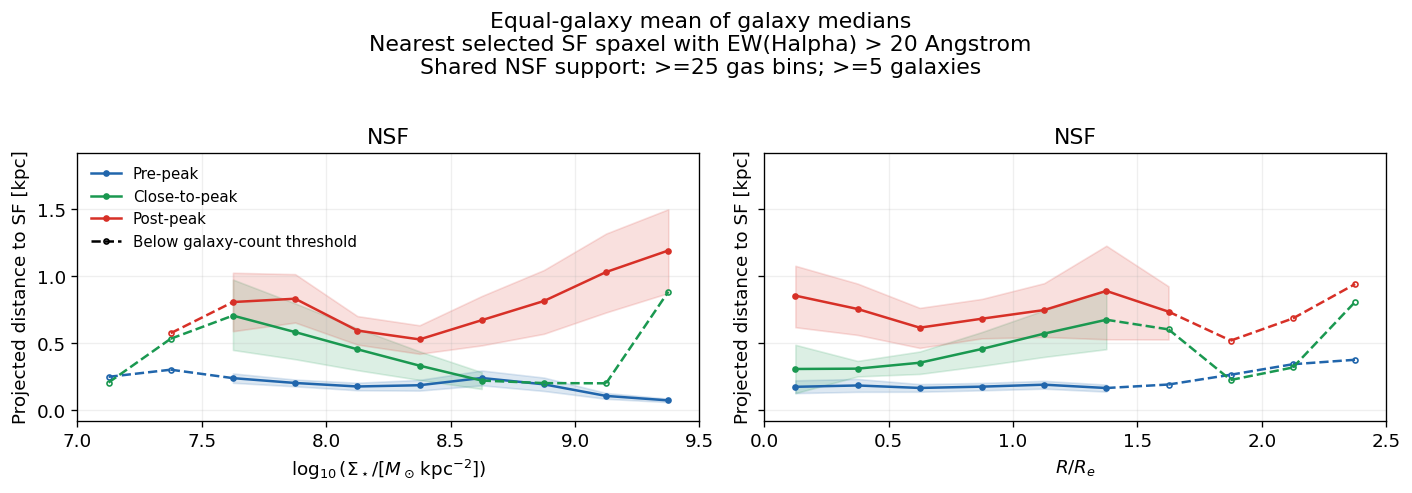

In [7]:
def plot_support_segments(ax, x, y, supported, color, label, ms=4):
    """Never bridge missing bins; any edge touching low-count data is dashed."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    supported = np.asarray(supported, bool)
    finite = np.isfinite(x) & np.isfinite(y)
    ax.plot([], [], color=color, marker='o', ms=ms, label=label)
    for j in range(len(x)-1):
        if finite[j] and finite[j+1]:
            style = '-' if supported[j] and supported[j+1] else '--'
            ax.plot(x[j:j+2], y[j:j+2], color=color, linestyle=style)
    for good, face in ((True, color), (False, 'none')):
        selected = finite & (supported == good)
        ax.plot(x[selected], y[selected], linestyle='none', marker='o', ms=ms,
                color=color, markerfacecolor=face)

DIAGNOSTIC_YLIMS = {}
for diagnostic in DIAGNOSTIC_ORDER:
    finite = PROFILES.loc[PROFILES.diagnostic.eq(diagnostic) & PROFILES.in_fixed_reliable_range,
                          ['display_value', 'value_lo', 'value_hi']].to_numpy().ravel()
    finite = finite[np.isfinite(finite)]
    if diagnostic == 'sigma_Ha':
        limits = DISPERSION_YLIM
    elif len(finite):
        padding = max(.05, .08 * np.ptp(finite))
        limits = (float(finite.min() - padding), float(finite.max() + padding))
    else:
        limits = (0., 1.)
    DIAGNOSTIC_YLIMS[diagnostic] = limits

def plot_diagnostic_profiles(branch, diagnostic):
    table = PROFILES.loc[PROFILES.weighting.eq(branch) & PROFILES.diagnostic.eq(diagnostic)]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex='col', sharey=True, squeeze=False)
    for ri, category in enumerate(CATEGORY_ORDER):
        for ci, variable in enumerate(VARIABLES):
            ax = axes[ri, ci]
            for stage in STAGE_ORDER:
                sub = table.loc[table.category.eq(category) & table.variable.eq(variable)
                                & table.stage.eq(stage)].sort_values('center')
                shown = sub.in_fixed_reliable_range & sub.eligible_stage
                x = sub.center.to_numpy(float)
                y = np.where(sub.in_fixed_reliable_range, sub.display_value, np.nan)
                yl, yh = (np.where(shown, sub[col].to_numpy(float), np.nan)
                          for col in ('value_lo', 'value_hi'))
                plot_support_segments(ax, x, y, sub.eligible_stage.to_numpy(bool),
                                      STAGE_COLORS[stage], STAGE_LABELS[stage], ms=3)
                ax.fill_between(x, yl, yh, color=STAGE_COLORS[stage], alpha=.15)
            ax.set_xlim(*FIXED_RELIABLE_RANGES[variable])
            ax.set_ylim(*DIAGNOSTIC_YLIMS[diagnostic])
            ax.set_title(category)
            ax.set_xlabel(VARIABLE_LABELS[variable])
            ax.set_ylabel(DIAGNOSTIC_LABELS[diagnostic])
            ax.grid(alpha=.2)
    axes[0, 0].plot([], [], 'k--', marker='o', markerfacecolor='none', ms=3,
                    label='Below galaxy-count threshold')
    axes[0, 0].legend(frameon=False, fontsize=9)
    if diagnostic == 'distance_SF_kpc':
        title = (BRANCH_LABELS[branch]
                 + '\nNearest selected SF spaxel with EW(Halpha) > 20 Angstrom'
                 + '\nShared NSF support: >=25 gas bins; >=5 galaxies')
    else:
        title = (BRANCH_LABELS[branch] + '\n' + DIAGNOSTIC_LABELS[diagnostic]
                 + ' | shared NSF support: >=25 gas bins; >=5 galaxies')
    fig.suptitle(title, y=1.02)
    fig.tight_layout()
    plt.show()

for diagnostic in DIAGNOSTIC_ORDER:
    plot_diagnostic_profiles('equal', diagnostic)

## Pooled-spaxel sensitivity

Literal supported-pixel medians; a galaxy with more selected pixels has more influence. Bootstrap resampling still operates on whole galaxies.

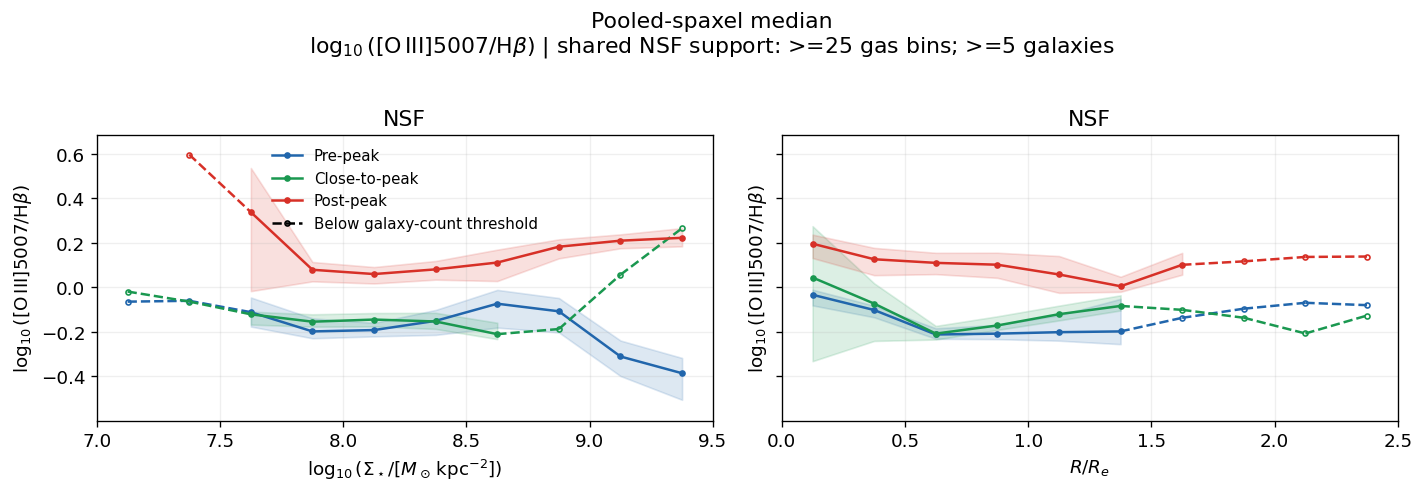

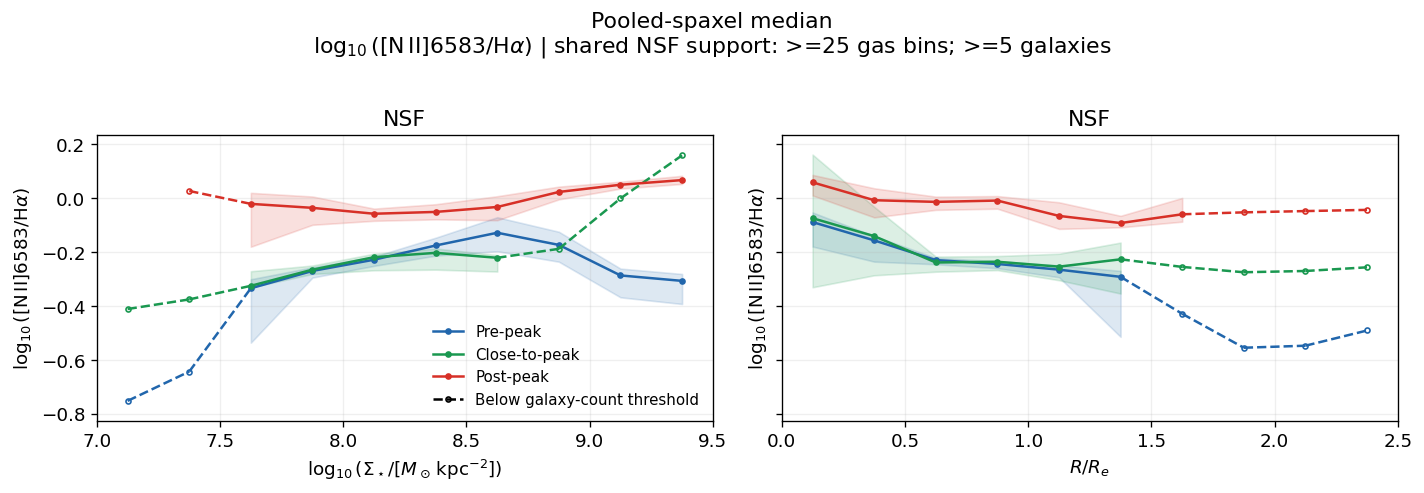

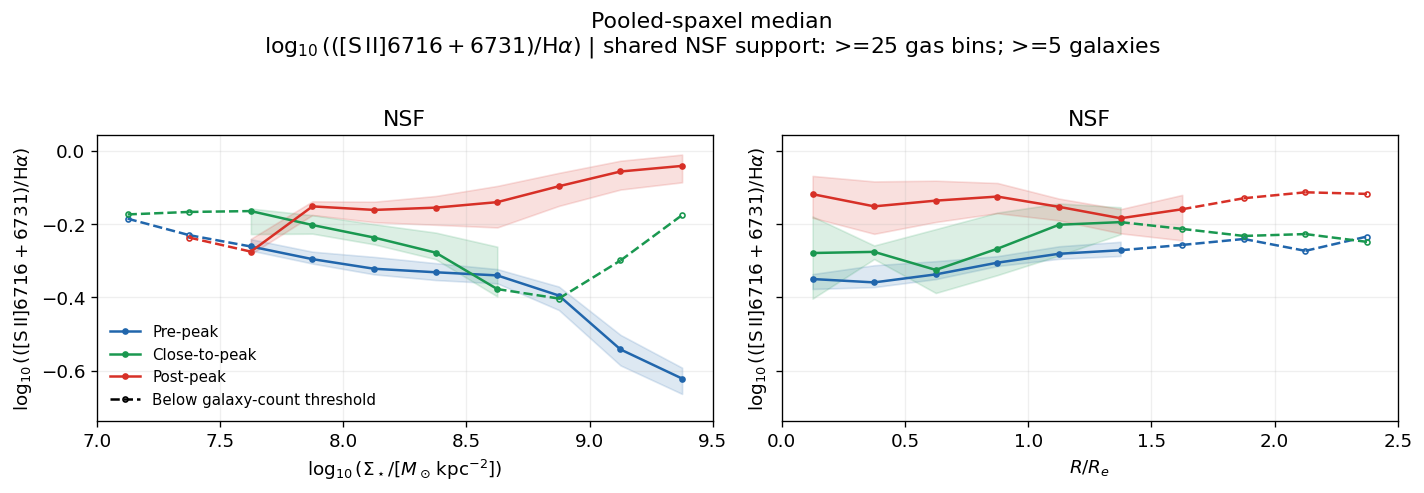

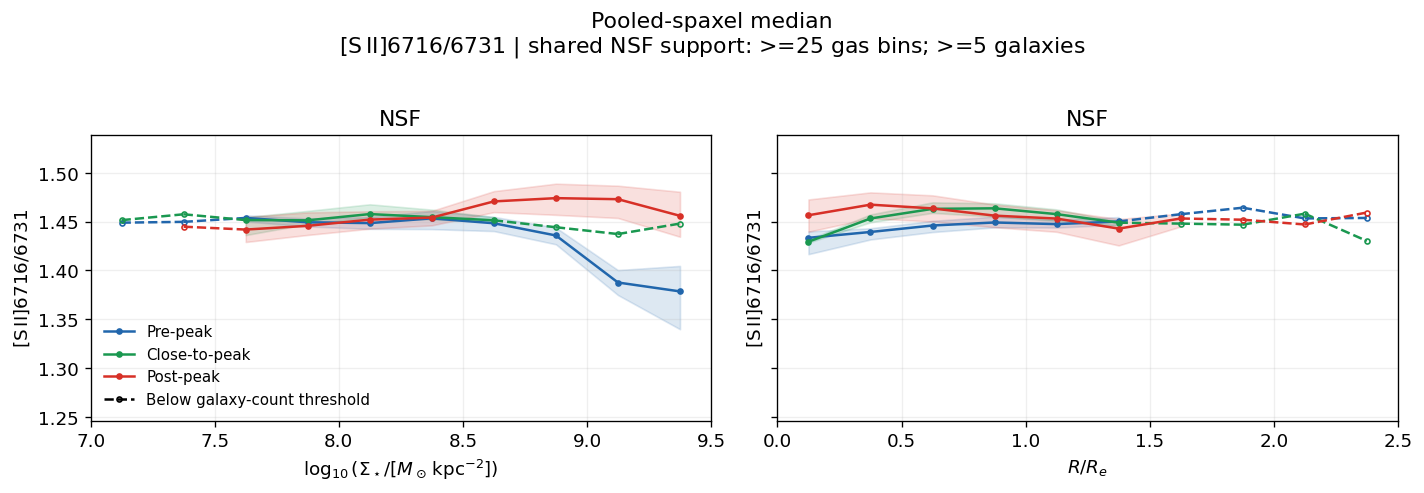

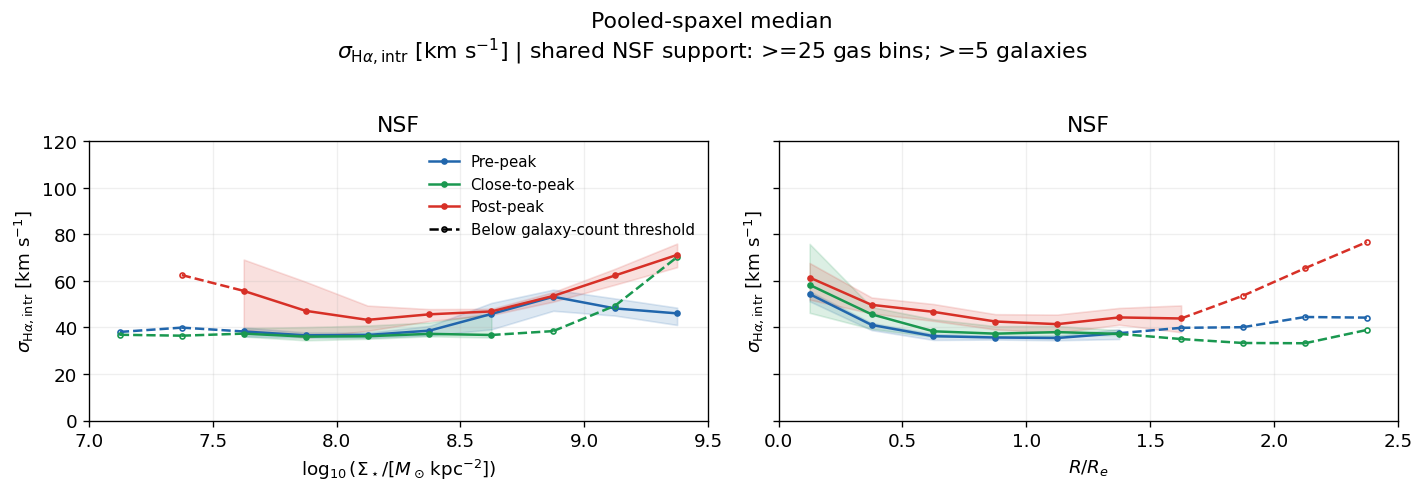

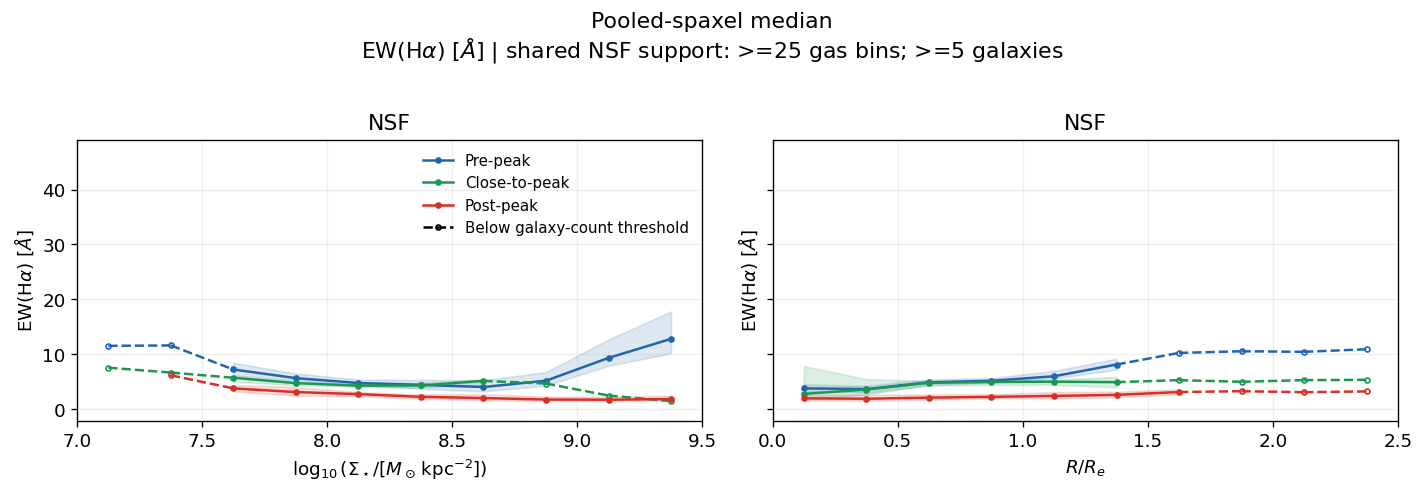

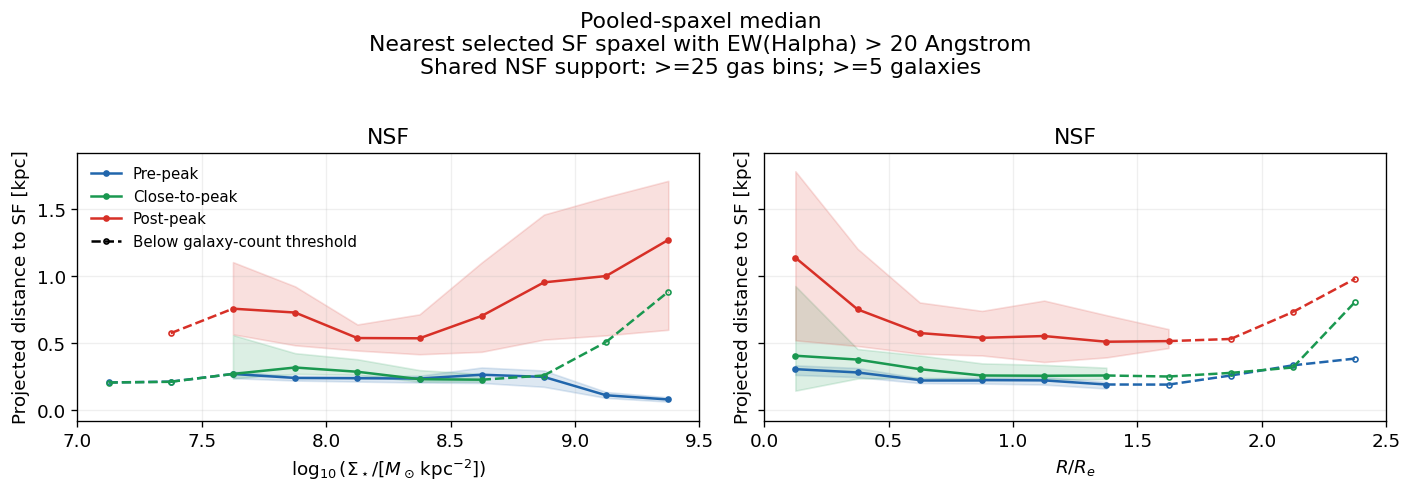

In [8]:
for diagnostic in DIAGNOSTIC_ORDER:
    plot_diagnostic_profiles('pooled', diagnostic)

## Numerical checks and full-range values

Cross-check every supported stage estimate against its contributing galaxy medians or concatenated finite pixels. Inspect observable-specific contributor counts using the support table; no extra per-observable count gate has been added.

In [9]:
checks = {
    'seven_diagnostics': set(MEASUREMENTS.diagnostic) == set(DIAGNOSTIC_ORDER),
    'NSF_only': set(MEASUREMENTS.category) == {'NSF'},
    'shared_nsf_support_gate': bool(NSF_SUPPORT_BY_GALAXY_BIN.NSF_eligible_galaxy.equals(
        nsf_profile_supported(NSF_SUPPORT_BY_GALAXY_BIN))),
    'finite_counts_within_selection': bool(MEASUREMENTS.N_pixels.le(MEASUREMENTS.N_selected).all()),
    'stage_gate': bool(PROFILES.eligible_stage.equals(
        PROFILES.N_NSF_gal_support.ge(MIN_GALAXIES_PER_STAGE_BIN))),
    'rejected_intervals_nan': bool(PROFILES.loc[~PROFILES.eligible_stage,
        ['value', 'value_lo', 'value_hi']].isna().all().all()),
    'finite_sigma_formula': bool(np.allclose(intrinsic_sigma_from_maps(
        np.array([50., 20., 10.]), np.array([30., 20., 20.])),
        [40., np.nan, np.nan], equal_nan=True)),
    'intervals_ordered': bool(PROFILES.dropna(subset=['value_lo', 'value_hi']).eval('value_lo <= value_hi').all()),
    'bootstrap_count_valid': bool(PROFILES.N_finite_bootstrap.between(0, N_BOOTSTRAP).all()),
}
indexed_measurements = {key: frame for key, frame in MEASUREMENTS.groupby(
    ['stage', 'variable', 'category', 'diagnostic', 'bin_left'], observed=True)}
central_checks = []
for row in PROFILES.itertuples(index=False):
    group = indexed_measurements[(row.stage, row.variable, row.category, row.diagnostic, row.bin_left)]
    use = group.loc[group.contributes]
    if row.eligible_stage and len(use):
        expected = (use.galaxy_median.mean() if row.weighting == 'equal'
                    else np.median(np.concatenate(use['values'].to_list())))
    else:
        expected = np.nan
    central_checks.append(np.allclose(row.value, expected, equal_nan=True))
checks['every_central_estimate_matches_definition'] = bool(all(central_checks))
sigma_reference = DISPERSION_BY_GALAXY_BIN.rename(columns={'N_sigma_Ha': 'N_reference'})
sigma_counts = MEASUREMENTS.loc[MEASUREMENTS.diagnostic.eq('sigma_Ha')].merge(
    sigma_reference[['GALID', 'variable', 'category', 'bin_left', 'N_reference']],
    on=['GALID', 'variable', 'category', 'bin_left'], validate='one_to_one')
checks['sigma_pixel_counts_match_source_support'] = bool(sigma_counts.N_pixels.eq(sigma_counts.N_reference).all())

for row in PROFILES.itertuples(index=False):
    group = indexed_measurements[(row.stage, row.variable, row.category, row.diagnostic, row.bin_left)]
    use = group.loc[group.contributes]
    expected = (use.galaxy_median.mean() if row.weighting == 'equal'
                else np.median(np.concatenate(use['values'].to_list()))) if len(use) else np.nan
    assert np.allclose(row.display_value, expected, equal_nan=True)
checks['descriptive_values_match_available_galaxies'] = True

display(pd.Series(checks, name='passed').to_frame())
assert all(checks.values()), checks
display(PROFILES.loc[PROFILES.in_fixed_reliable_range])
OUTSIDE_SIGMA_DISPLAY = PROFILES.loc[PROFILES.diagnostic.eq('sigma_Ha')
    & PROFILES.in_fixed_reliable_range & PROFILES.value.gt(DISPERSION_YLIM[1])]
display(OUTSIDE_SIGMA_DISPLAY)
print('SEVEN_DIAGNOSTICS_NOTEBOOK_VALIDATION_OK')

SEVEN_DIAGNOSTICS_NOTEBOOK_VALIDATION_OK


,passed
seven_diagnostics,True
NSF_only,True
shared_nsf_support_gate,True
finite_counts_within_selection,True
stage_gate,True
rejected_intervals_nan,True
finite_sigma_formula,True
intervals_ordered,True
bootstrap_count_valid,True
every_central_estimate_matches_definition,True


,weighting,stage,variable,category,diagnostic,bin_left,bin_right,center,N_NSF_gal_support,N_gal_support,N_spaxel_support,eligible_stage,N_finite_bootstrap,in_fixed_reliable_range,display_value,value,value_lo,value_hi
10,equal,pre-peak,log_sigma_star,NSF,EW_Ha,7.00,7.25,7.125,2,2,25765,False,0,True,10.551656,NaN,NaN,NaN
11,pooled,pre-peak,log_sigma_star,NSF,EW_Ha,7.00,7.25,7.125,2,2,25765,False,0,True,11.504961,NaN,NaN,NaN
12,equal,pre-peak,log_sigma_star,NSF,EW_Ha,7.25,7.50,7.375,3,3,40111,False,0,True,14.230349,NaN,NaN,NaN
13,pooled,pre-peak,log_sigma_star,NSF,EW_Ha,7.25,7.50,7.375,3,3,40111,False,0,True,11.580402,NaN,NaN,NaN
14,equal,pre-peak,log_sigma_star,NSF,EW_Ha,7.50,7.75,7.625,8,8,115120,True,10000,True,9.626214,9.626214,7.446424,11.910367
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2219,pooled,post-peak,radius_re,NSF,sigma_Ha,1.75,2.00,1.875,4,4,37374,False,0,True,53.633626,NaN,NaN,NaN
2220,equal,post-peak,radius_re,NSF,sigma_Ha,2.00,2.25,2.125,3,3,25335,False,0,True,54.730221,NaN,NaN,NaN
2221,pooled,post-peak,radius_re,NSF,sigma_Ha,2.00,2.25,2.125,3,3,25335,False,0,True,65.421244,NaN,NaN,NaN
2222,equal,post-peak,radius_re,NSF,sigma_Ha,2.25,2.50,2.375,2,2,15872,False,0,True,83.691130,NaN,NaN,NaN


,weighting,stage,variable,category,diagnostic,bin_left,bin_right,center,N_NSF_gal_support,N_gal_support,N_spaxel_support,eligible_stage,N_finite_bootstrap,in_fixed_reliable_range,display_value,value,value_lo,value_hi
